# 08. Save progress when the network disappears

Trace durable drafts, confirmed checkpoints, and stable operation identifiers through a retryable save.

**60 minutes including practice · Canopy**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-08) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can identify the last locally confirmed checkpoint in an interrupted save.
- You can explain how retrying the same operation differs from creating a new operation.
- You can test a lost acknowledgement without mistaking it for a failed server write.

## Before you begin

You can distinguish a captured original, a prepared derivative, and an uploaded photo.

You understand owner-scoped requests and runtime validation.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


Imagine saving a tree beside a trail. The server creates the plant, but your connection disappears before its reply reaches the phone. From the phone's point of view, the outcome is uncertain. Retrying with a new identifier could create a second record. Declaring the save complete could hide missing work. A useful offline design must preserve what it knows and acknowledge what it does not know.

Plantopedia uses a local draft as a record of the intended work and its confirmed progress. On native devices, SQLite holds the draft and app document storage holds retained files. The outbox then performs the cloud steps in order. This lesson uses that actual path; the browser's local.web.ts draft Map is a preview implementation and does not establish survival across a browser reload.


## Give each kind of memory a clear job

Component state answers what the current screen should show. Query's cache answers what the client last learned from the server. A durable draft answers what this owner intended to save and how far that work was confirmed. These records have different lifetimes. If you keep the only copy of an unsent observation in useState, leaving the route or restarting the app may lose it.

The native draft table uses owner and id together as its primary key. Every read and write should preserve that scope. The teaching helpers below use the existing lazy database() opener and Draft schema. The placeholders pass values separately from the SQL text, and reading parses the stored JSON back through the schema. Production local.ts already provides these operations; this excerpt exists to explain their responsibilities, not to create another competing table.

There is a further platform distinction. The separate feature-storage.web.ts uses browser localStorage for feature documents, while local.web.ts keeps the capture draft/cache preview in memory. Saying that every web feature is in memory would be inaccurate. Saying that capture drafts therefore have the same durable recovery as native SQLite would also be inaccurate. Always trace the specific abstraction a feature uses.


**Existing-database teaching excerpt: draftStorage.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
import { database } from '../services/local';
import { Draft } from '../services/local-schema';

export async function persistDraft(input: unknown) {
  const draft = Draft.parse(input);
  const db = await database();
  await db.runAsync(
    'INSERT OR REPLACE INTO drafts(owner,id,value) VALUES (?,?,?)',
    draft.owner, draft.id, JSON.stringify(draft),
  );
}

export async function readDrafts(owner: string) {
  const db = await database();
  const rows = await db.getAllAsync<{ value: string }>(
    'SELECT value FROM drafts WHERE owner = ?', owner,
  );
  return rows.map(row => Draft.parse(JSON.parse(row.value)));
}
```


## A checkpoint means the client confirmed a completed step

The current cloud outbox follows draft → plant → observation → photo → complete. At draft, the app still needs to create the plant. At plant, the plant request has completed and that checkpoint has been saved locally. At observation, it is ready to upload the prepared photo. At photo, the upload has been confirmed. Complete means this save workflow is finished; it does not mean the plant has a verified species.

The schema still accepts an identified stage for compatibility, but the present save path does not need to enter that stage. Identification happens through a separate deliberate operation. This separation lets a person preserve their photograph even when a provider is unavailable or returns uncertain evidence.

The outbox advances a checkpoint after the corresponding awaited operation succeeds. If the following local save fails, the server may be ahead of the local checkpoint. That is one reason retries need stable identities. A checkpoint is the client's confirmed knowledge, not an infallible statement about everything the server may have done. The running Set prevents duplicate in-flight work in this JavaScript process, but it is not a durable cross-device lock.


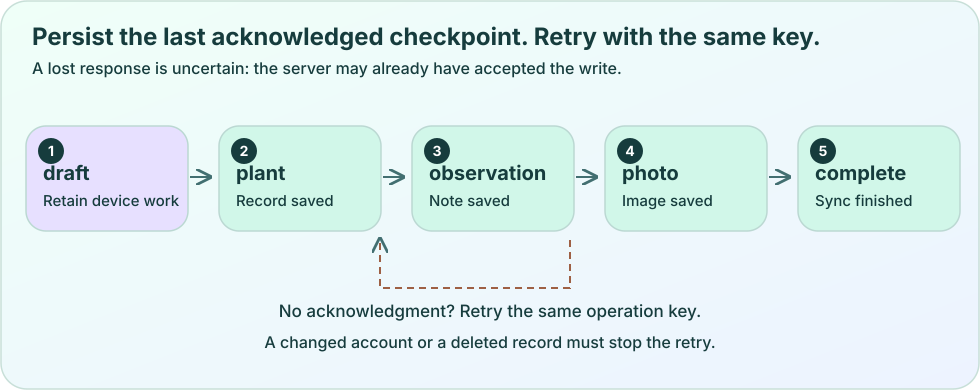

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Durable outbox checkpoints</title><desc id="desc">The native save flow acknowledges plant, observation, and photo stages before completing. A lost acknowledgment triggers retry with a stable operation key. Owner changes and deleted records stop replay.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">Persist the last acknowledged checkpoint. Retry with the same key.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">A lost response is uncertain: the server may already have accepted the write.</text><rect x="26" y="126" width="162" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="51" cy="151" r="13" fill="#163c3d"/><text x="51" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="43" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">draft</text><text x="43" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Retain device work</text><path d="M190 177L210 177" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="219" y="126" width="162" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="244" cy="151" r="13" fill="#163c3d"/><text x="244" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="236" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">plant</text><text x="236" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Record saved</text><path d="M383 177L403 177" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="412" y="126" width="162" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="437" cy="151" r="13" fill="#163c3d"/><text x="437" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="429" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">observation</text><text x="429" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Note saved</text><path d="M576 177L596 177" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="605" y="126" width="162" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="630" cy="151" r="13" fill="#163c3d"/><text x="630" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">4</text><text x="622" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">photo</text><text x="622" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Image saved</text><path d="M769 177L789 177" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="798" y="126" width="162" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="823" cy="151" r="13" fill="#163c3d"/><text x="823" y="156" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">5</text><text x="815" y="180" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">complete</text><text x="815" y="206" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">Sync finished</text><path d="M570 240V288H380V239" fill="none" stroke="#9e6044" stroke-width="2" stroke-dasharray="7 5" marker-end="url(#arrow)"/><text x="490" y="317" font-size="17" fill="#163c3d" font-weight="500" text-anchor="middle">No acknowledgment? Retry the same operation key.</text><text x="490" y="348" font-size="16" fill="#163c3d" font-weight="500" text-anchor="middle">A changed account or a deleted record must stop the retry.</text></g></svg>'))


> **Confirmed locally and completed remotely can differ**
>
> When an acknowledgement is lost, the server may have committed a step while the phone still has the earlier checkpoint. Recovery must work with that uncertainty.


## Retry the same intended operation

An idempotency key identifies one intended operation so the server can recognize a retry. Plantopedia derives stable keys such as plant_<draft-id>, observation_<draft-id>, and photo_<draft-id>. The server also compares the operation type and payload. Reusing a key with a different payload is a conflict, because the same operation cannot quietly change its meaning halfway through.

The following self-contained JavaScript-style TypeScript model deliberately uses an in-memory server result to isolate one idea. Call clientAttempt(true), observe the simulated lost acknowledgement, and then call clientAttempt(false). The saved size remains one because the second call has the same operation key and payload. A real server additionally needs authentication, durable transactions, conflict checks, deletion rules, and concurrency handling. This model supplies none of those production guarantees.

The actual draft records submittedAt before the first cloud write. The capture form stops ordinary edits after that submission snapshot, which preserves the payload associated with a possibly completed operation. Only a specific typed pre-write input rejection makes that draft editable again. A generic network failure is not proof that the server did nothing.


**Teaching model: lostAcknowledgement.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
const saved = new Map<string, { nickname: string }>();
const operationKey = 'plant_draft_42';
const frozenPayload = { nickname: 'Trail maple' };

async function serverSave(key: string, payload: { nickname: string }) {
  const previous = saved.get(key);
  if (previous) {
    if (previous.nickname !== payload.nickname) throw new Error('Conflict');
    return previous;
  }
  const result = { ...payload };
  saved.set(key, result);
  return result;
}

export async function clientAttempt(loseAcknowledgement: boolean) {
  const result = await serverSave(operationKey, frozenPayload);
  if (loseAcknowledgement) throw new Error('Reply was lost after commit');
  return { result, serverRecordCount: saved.size };
}
// await clientAttempt(true) rejects after the server has saved.
// await clientAttempt(false) returns the same result and count 1.
```


## Recover without overwriting evidence or changing owners

Photo recovery has a special case. The upload may have succeeded before its acknowledgement was lost, and a cached derivative may have disappeared later. Before recreating an expired derivative at the observation checkpoint, resumeDraftPhoto asks for plant detail and looks for the matching photo, observation, and capture time. If it finds them, it can resume at photo. If bytes must be prepared again, stable identifiers and server conflict rules still prevent silently overwriting an uncertain earlier upload.

Deletion is another boundary. A server tombstone records that a specimen was deleted, so an old draft cannot simply resurrect it by retrying. A record_deleted failure should remain visible rather than turning into a new plant with a new identifier behind the person's back. Likewise, a draft for one owner must never become work for the next account. The outbox checks the supplied sameUser predicate between stages, and the session disposes old API work when its owner changes.

A good retry button names the unfinished work and preserves the last known draft. Do not retry every error endlessly. Permission failures, validation failures, deletion, and uncertain provider outcomes need different responses from a brief lost connection. In the lab, advance until a failure, restore the connection, and compare the operation keys before and after retry. Your explanation should focus on what the app knows at each point.


## Experiment: predict, change, explain

First run the SQLite write/close/reopen check and explain what the second connection can retrieve for each owner. Then toggle lost acknowledgement and account change. Defaults lose the first acknowledgement while keeping the original owner. The retry model attempts only plant creation, at most twice, and prints its trace; it does not advance the full observation/photo pipeline. Predict the distinct-write count and confirmed checkpoint before changing a flag, then use the browser outbox lab for the longer sequence.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
import sqlite3
from contextlib import closing
from pathlib import Path
from tempfile import TemporaryDirectory

# Real SQLite write and reopen, in a disposable local folder. No cloud service.
# This models metadata durability, not camera files or expo-sqlite itself.
with TemporaryDirectory(prefix='plantopedia-course-') as folder:
    path = Path(folder) / 'drafts.db'
    # A Connection context manager commits/rolls back; closing also closes its file.
    with closing(sqlite3.connect(path)) as db:
        with db:
            db.execute('CREATE TABLE drafts (owner TEXT, id TEXT, stage TEXT, PRIMARY KEY(owner, id))')
            db.execute('INSERT INTO drafts VALUES (?, ?, ?)', ('learner_a', 'fern_01', 'draft'))
    # The first connection is committed AND closed before a separate connection opens.
    with closing(sqlite3.connect(path)) as reopened:
        row = reopened.execute('SELECT stage FROM drafts WHERE owner = ? AND id = ?', ('learner_a', 'fern_01')).fetchone()
        other = reopened.execute('SELECT stage FROM drafts WHERE owner = ?', ('learner_b',)).fetchone()
    assert row == ('draft',) and other is None
    # Verify cleanup before TemporaryDirectory attempts removal, including on Windows.
    for connection in (db, reopened):
        try:
            connection.execute('SELECT 1')
        except sqlite3.ProgrammingError:
            pass  # The expected result for an explicitly closed connection.
        else:
            raise AssertionError('Close the database connection before deleting its folder')
print('A committed metadata draft survived reopening; another owner did not retrieve it.')

def retry_model(lose_first_ack=True, change_owner=False):
    accepted, checkpoint, trace = set(), 'draft', []
    for attempt in range(1, 3):
        if change_owner:
            trace.append('STOP: account changed before sending.'); break
        key = 'plant_fern_01'  # stable across BOTH attempts
        existed = key in accepted
        accepted.add(key)
        trace.append(f'Attempt {attempt}: ' + ('reuse prior result' if existed else 'accept one write'))
        if attempt == 1 and lose_first_ack:
            trace.append('Response lost. Keep draft checkpoint.'); continue
        checkpoint = 'plant'
        break
    return len(accepted), checkpoint, trace

def explore_retry(lose_first_ack=True, change_owner=False):
    writes, checkpoint, trace = retry_model(lose_first_ack, change_owner)
    print('\n'.join(trace)); print('Distinct writes:', writes, '| checkpoint:', checkpoint)

explore(explore_retry, lose_first_ack=True, change_owner=False)
assert retry_model(True, False)[:2] == (1, 'plant')
assert retry_model(False, False)[:2] == (1, 'plant')
assert retry_model(True, True)[:2] == (0, 'draft')


A committed metadata draft survived reopening; another owner did not retrieve it.


interactive(children=(Checkbox(value=True, description='lose_first_ack'), Checkbox(value=False, description='c…

## Make a prediction of your own

Predict distinct writes after the first acknowledgment is lost and the same key is retried.

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with retry_model(True, False)[0].
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 1:
    print('Correct. '+'The fixture server remembers the stable operation key. It returns the existing result instead of creating a duplicate.')
else:
    print('Revisit your prediction. '+'The fixture server remembers the stable operation key. It returns the existing result instead of creating a duplicate.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. The server saved a plant, but its reply never reached the phone. What is the safest retry?**

1. Generate a new draft ID because every tap must be a new operation.
2. Reuse the frozen payload and the original operation identity.
3. Mark all remaining steps complete.

**2. Does TanStack Query's in-memory cache replace a durable native draft?**

1. No. A draft must preserve intended work and checkpoints across process restarts.
2. Yes. A query key guarantees persistence.
3. Yes, if the cache contains a URI string.

**3. The current outbox reaches complete. What can the interface claim?**

1. The species is verified.
2. Every platform has identical offline recovery.
3. The plant, observation, and photo save workflow has completed.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': 'The server saved a plant, but its reply never reached the phone. What is the safest retry?', 'options': ['Generate a new draft ID because every tap must be a new operation.', 'Reuse the frozen payload and the original operation identity.', 'Mark all remaining steps complete.'], 'answer': 1, 'explanation': 'The server can recognize the original operation and return its recorded result. A new identity may create duplicate work. The lost reply proves neither that the write failed nor that the later observation and photo steps completed.'}, {'question': "Does TanStack Query's in-memory cache replace a durable native draft?", 'options': ['No. A draft must preserve intended work and checkpoints across process restarts.', 'Yes. A query key guarantees persistence.', 'Yes, if the cache contains a URI string.'], 'answer': 0, 'explanation': 'Query cache and durable intent have different responsibilities. A key separates cached data but does not by itself write a draft or retain a physical file. A URI is useful only while the referenced resource remains available.'}, {'question': 'The current outbox reaches complete. What can the interface claim?', 'options': ['The species is verified.', 'Every platform has identical offline recovery.', 'The plant, observation, and photo save workflow has completed.'], 'answer': 2, 'explanation': 'Identification is an independent action in the current implementation. Native SQLite/file recovery and the browser draft preview are different. A completed save should be described precisely without claiming unrelated work succeeded.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Write a failure diary for one draft

Use a synthetic specimen and record both local knowledge and remote state through interrupted saves. The goal is a recoverable sequence, not a claim that every request executes exactly once.

1. Create a table with columns for event, local checkpoint, remote records, operation key, and next action.
2. Trace a normal save through draft, plant, observation, photo, and complete.
3. Repeat the trace with a lost acknowledgement immediately after plant creation, then retry with the same key and payload.
4. Repeat with a successful photo upload whose reply is lost and whose cached derivative later expires.
5. Add an account change and a server deletion; explain why neither permits silently replaying the draft as new work.

### Check your result

- [ ] The trace distinguishes a remote commit from a received acknowledgement.
- [ ] Retry preserves IDs and the submitted payload.
- [ ] A failed step leaves evidence and the last confirmed checkpoint available.
- [ ] Your web/native comparison names the actual storage abstraction instead of making one claim about all browser data.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Ask two questions after every awaited operation: what might have happened remotely, and what has been recorded locally? They may have different answers.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
After a lost plant acknowledgement, the local checkpoint can remain draft while the server already has the plant. Retry uses plant_<same-id> with the original payload, so the server returns the prior result and the client can record plant. Observation follows the same principle. If an uploaded photo is found during resume, move to photo without uploading another image. An owner change stops old work; a record_deleted result preserves the failure instead of resurrecting the record. No table row should claim that a missing reply proves a rollback.
```

</details>


## Explain it in your own words

Why can an operation guard in a JavaScript Set reduce duplicate taps while still being insufficient after an app restart? Explain which responsibilities belong to local persistence and which belong to the server.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/services/outbox.ts](../../../src/services/outbox.ts) — The save path advances checkpoints, preserves failures, uses stable operation keys, and checks the owner predicate.

- [src/services/local.ts](../../../src/services/local.ts) — Native SQLite and retained document files provide draft persistence.

- [src/services/local.web.ts](../../../src/services/local.web.ts) — The capture draft/cache browser preview uses Maps and has a different lifetime.

- [src/features/capture/resume.ts](../../../src/features/capture/resume.ts) — Recovery can find an acknowledged-by-server photo before recreating an expired derivative.

- [server/src/application/core.ts](../../../server/src/application/core.ts) — Durable server operations compare type/payload hashes, recognize retries, and honor deleted records.

- [tests/components/outbox.test.tsx](../../../tests/components/outbox.test.tsx) — Existing tests cover retained failure details, metadata rejection, and stopping work after an account change.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [Expo SDK 57: SQLite persistence](https://docs.expo.dev/versions/v57.0.0/sdk/sqlite/)
- [TanStack Query v5: query keys](https://tanstack.com/query/latest/docs/framework/react/guides/query-keys)


## Carry these ideas forward

- A durable draft records intended work and locally confirmed checkpoints.
- Stable operation identity and frozen payloads make uncertain retries safer.
- Lost acknowledgements, owner changes, and deletion are first-class recovery cases.
